# Metamodel validation (propagation holdout)

Three steps:

1. **Fit** — `mm.fit(goal)` or `mm.fit_all()` (every metamodel set in
   `metamodel.sets`: one PCA + GP per group of output sites, same SnapWave cases
   and MDA)
2. **Validate** — `val.sweep(goal, metamodel=…)` for metrics;
   `val.validate(goal, n, metamodel=…)` for plotting
3. **Plot** — `result.plot('10m')`, `result.plot_all()`, …

Validation loads saved models only (no refitting). Holdout metrics and plots
include **`hs`, `tp`, `dir`, `spr`**. The sites removed by the site filter are
in `outputs/goal_XX/split.json` (`mm.removed_sites(goal)`); fitting details in
`logs/metamodel.log`.

In [1]:
import matplotlib.pyplot as plt
from utils import metamodel as mm
from utils import validation as val
from utils.config import METAMODEL, load_goals

In [ ]:
goals = list(load_goals().keys())
mm_set = "isobaths"  # metamodel set to validate and plot (see metamodel.sets)
candidates = METAMODEL["mda_candidates"]
metrics = METAMODEL["validation"]["metrics_variables"]
site_filter = METAMODEL["site_filter"]

print(f"goals      : {goals}")
print(f"sets       : {METAMODEL['sets']} (plotting {mm_set!r})")
print(f"candidates : {candidates}")
print(f"metrics    : {metrics}")
print(f"MDA max    : {max(mm.MDA_CANDIDATES)} (test cases = plausible cases - max)")
for key, threshold in site_filter.items():
    if key.endswith("_ratio_max"):
        var = key[:-10]
        print(
            f"{var} filter : > {threshold} x {var}_forcing removed before PCA (site_filter)"
        )
    elif key.endswith("_max"):
        var = key[:-4]
        print(f"{var} filter : > {threshold} removed before PCA (site_filter)")
    elif key.endswith("_min"):
        var = key[:-4]
        print(f"{var} filter : < {threshold} removed before PCA (site_filter)")
print(
    "PCA NaN    : safety net only (sites are wet; zero-energy fields filled with the forcing)"
)

goals      : ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
sets       : {'buoys': {'sites': 'buoy'}, 'isobaths': {'sites': 'isobath'}, 'deenhaag': {'sites': 'DeenHaag'}} (plotting 'isobaths')
candidates : [100, 550]
metrics    : ['hs', 'tp', 'dir', 'spr']
MDA max    : 550 (test cases = plausible cases - max)
hs filter : > 3.0 x hs_forcing removed before PCA (site_filter)
tp filter : < 0.5 removed before PCA (site_filter)
hs_nan filter : > 0.01 removed before PCA (site_filter)
PCA NaN    : safety net only (sites are wet; zero-energy fields filled with the forcing)


## 1 · Fit

In [3]:
# All goals; existing fits are kept (force_retrain=True to refit). A long fit can
# run as a script from the case folder with the same call, setting
# os.environ["OMP_NUM_THREADS"] (e.g. "16") before importing utils.
# mm.fit_all(gp_epochs=5000)

## 2 · Validate

In [4]:
# Metrics for every MDA size → outputs/goal_01/{mm_set}/validation_metrics.csv
metrics = val.sweep(4, metamodel=mm_set)
metrics.head()

,goal,metamodel,mda_candidate,n_test_cases,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,rrmse,si,r,r2,reference_label,estimate_label
0,4,isobaths,100,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,hs,Hs,92825,-1.093195e-03,1.728943e-01,3.085971e-01,1.903377e-01,0.970377,0.941523,SnapWave,Metamodel
1,4,isobaths,100,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,tp,Tp,92825,2.964664e-08,9.336415e-07,8.754602e-08,8.449107e-08,1.000000,1.000000,SnapWave,Metamodel
2,4,isobaths,100,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,dir,Dir,92825,-2.202148e-01,1.001547e+01,NaN,NaN,NaN,0.958002,SnapWave,Metamodel
3,4,isobaths,100,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,spr,Spr,92825,-1.154574e-01,5.361196e+00,2.064074e-01,1.797230e-01,0.931153,0.866187,SnapWave,Metamodel
4,4,isobaths,100,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,hs,Hs,148046,6.491855e-03,1.420714e-01,3.012270e-01,1.591932e-01,0.982307,0.964734,SnapWave,Metamodel


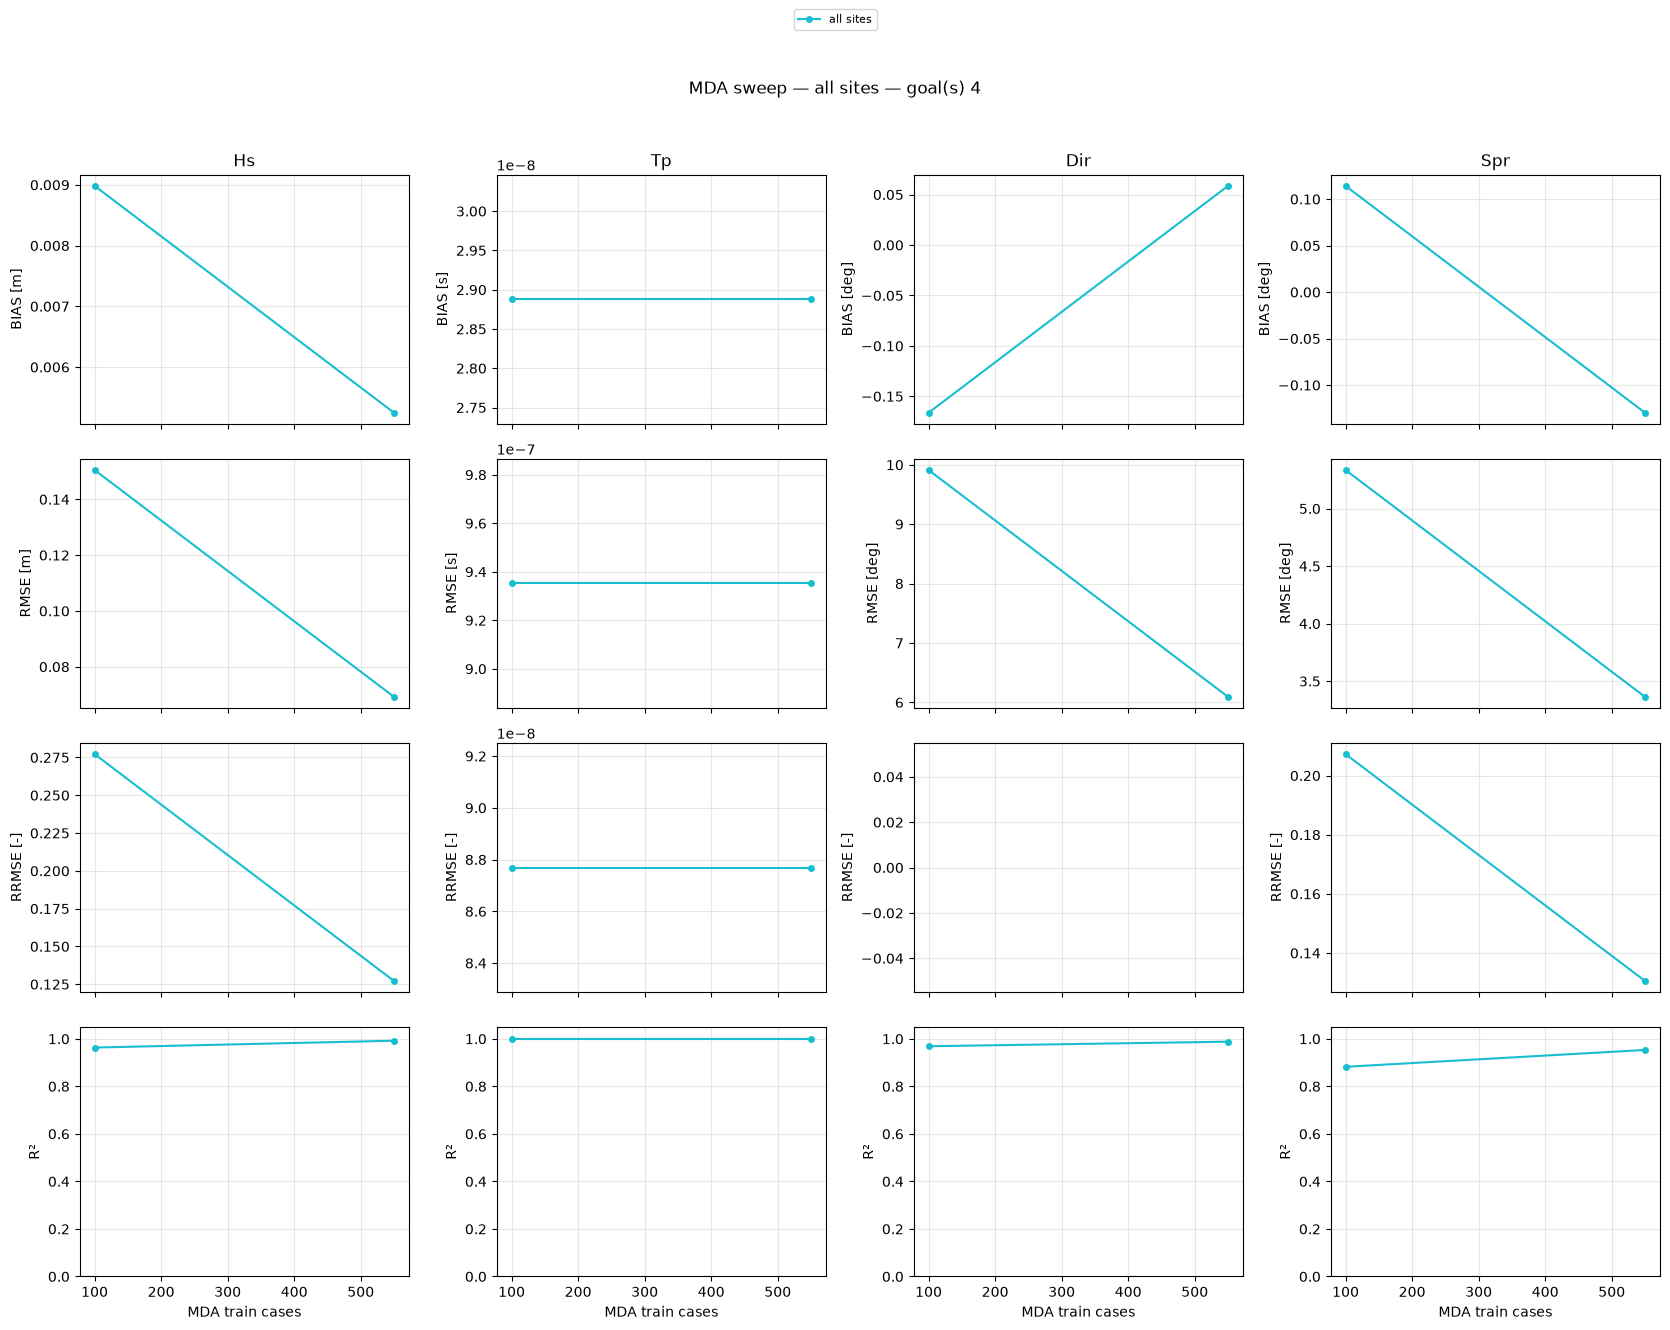

In [5]:
val.plot_sweep(metrics, by="bulk")
plt.show()

## 3 · Plot

In [6]:
n = 550  # MDA size to plot
result = val.validate(4, n, metamodel=mm_set)

# Available groups: isobath depths, mesh labels, buoy ids
result.groups

['5m', '10m', '20m']

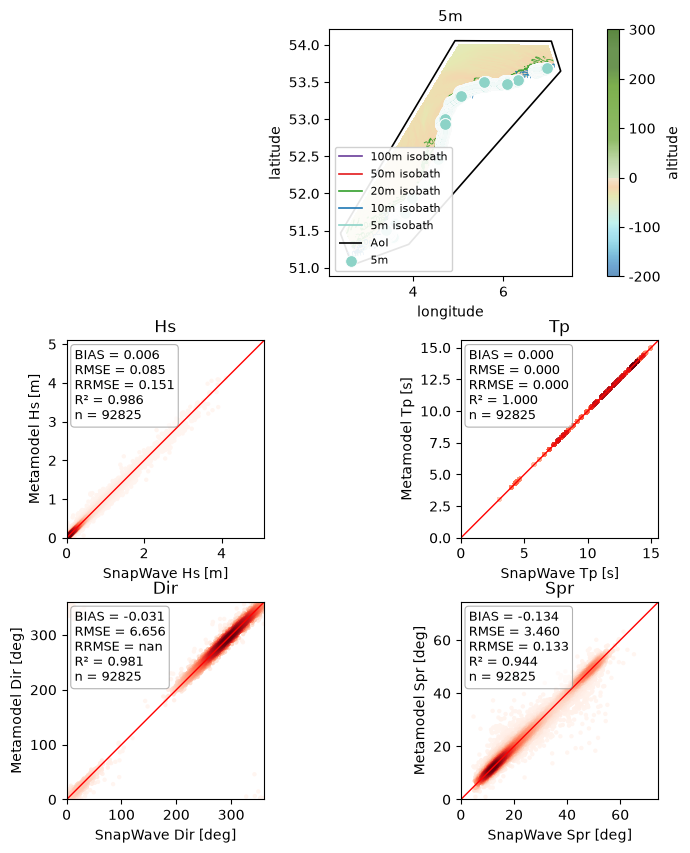

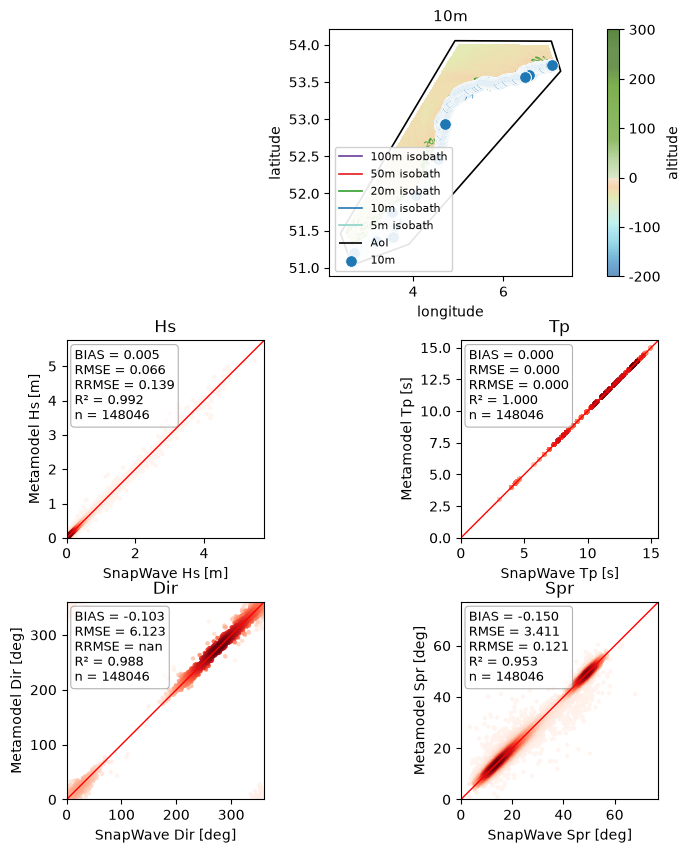

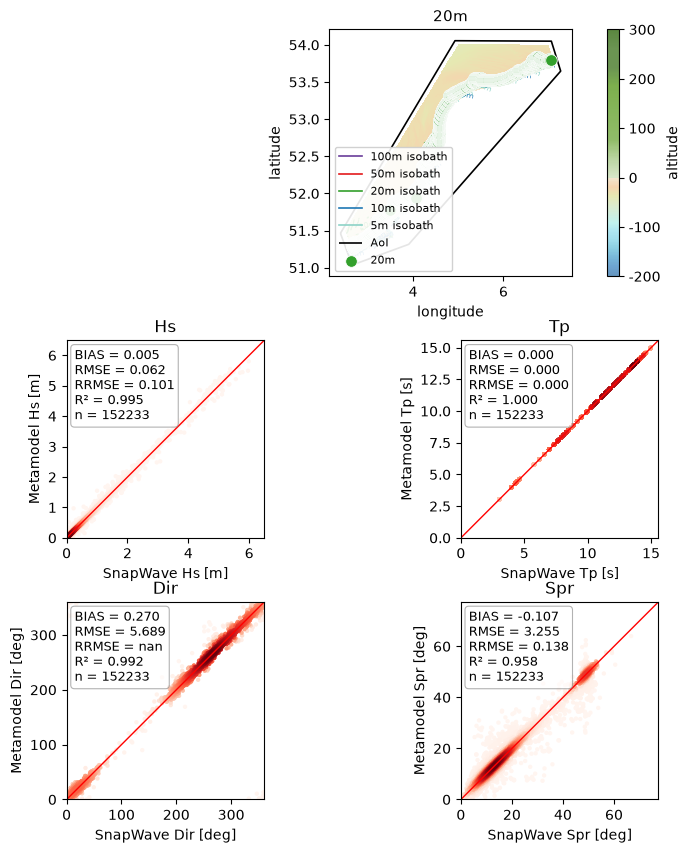

In [7]:
# One group, scatters only
# result.plot_scatter("10m", variables=["hs"])

# All groups (map + scatters)
for fig in result.plot_all():
    plt.show()

## All goals

In [8]:
all_metrics = val.sweep_all()  # every goal and metamodel set
all_metrics

,goal,metamodel,mda_candidate,n_test_cases,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,rrmse,si,r,r2,reference_label,estimate_label
0,1,buoys,100,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_A2,buoy,waves,hs,Hs,79,8.180808e-02,2.295306e-01,1.462421e-01,1.158764e-01,0.975955,0.945225,SnapWave,Metamodel
1,1,buoys,100,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_A2,buoy,waves,tp,Tp,79,2.463488e-07,1.008052e-06,9.540449e-08,8.971208e-08,1.000000,1.000000,SnapWave,Metamodel
2,1,buoys,100,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_A2,buoy,waves,dir,Dir,79,-2.171380e-01,1.010523e+01,NaN,NaN,NaN,0.984249,SnapWave,Metamodel
3,1,buoys,100,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_A2,buoy,waves,spr,Spr,79,6.213196e-01,4.692940e+00,1.832312e-01,1.679591e-01,0.904940,0.801647,SnapWave,Metamodel
4,1,buoys,100,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_AWG,buoy,waves,hs,Hs,79,-2.006180e-03,1.000254e-02,7.466244e-01,2.963193e-01,0.970342,0.890553,SnapWave,Metamodel
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3355,10,deenhaag,100,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",DeenHaag,mesh,DeenHaag,spr,Spr,11139,4.621946e-01,6.909581e+00,1.723731e-01,1.600428e-01,0.900889,0.808099,SnapWave,Metamodel
3356,10,deenhaag,550,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",DeenHaag,mesh,DeenHaag,hs,Hs,11139,1.242334e-03,2.406114e-02,6.361455e-01,2.504169e-01,0.962641,0.925557,SnapWave,Metamodel
3357,10,deenhaag,550,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",DeenHaag,mesh,DeenHaag,tp,Tp,11139,1.378172e-07,9.273921e-07,8.764977e-08,8.407941e-08,1.000000,1.000000,SnapWave,Metamodel
3358,10,deenhaag,550,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",DeenHaag,mesh,DeenHaag,dir,Dir,11139,1.788725e-01,5.261305e+00,NaN,NaN,NaN,0.996111,SnapWave,Metamodel


In [9]:
# Best MDA size per goal (10m isobath, Hs)
hs_10m = all_metrics.query("site_label == '10m' and variable == 'hs'")
best = hs_10m.loc[hs_10m.groupby("goal")["rmse"].idxmin()]
best[["goal", "mda_candidate", "site_label", "rmse", "r2", "n"]]

,goal,mda_candidate,site_label,rmse,r2,n
320,1,550,10m,0.092598,0.988063,148125
3344,10,550,10m,0.072819,0.985319,148125
656,2,550,10m,0.083935,0.991084,148125
992,3,550,10m,0.068050,0.991275,148125
1328,4,550,10m,0.065784,0.992439,148046
1664,5,550,10m,0.075072,0.990351,148125
2000,6,550,10m,0.075701,0.985326,148125
2336,7,550,10m,0.056991,0.990699,148125
2672,8,550,10m,0.062356,0.989011,148125
3008,9,550,10m,0.065597,0.990260,148125
